# **Bikewale-Project**

In [144]:
import requests

In [145]:
url = "https://www.bikewale.com/new-bikes-in-india/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"
}

response = requests.get(url, headers=headers)
print("Status code:", response.status_code)

with open("bikewale_page.html", "w", encoding="utf-8") as f:
    f.write(response.text)

print("Saved! Open bikewale_page.html in your browser or a text editor.")

Status code: 200
Saved! Open bikewale_page.html in your browser or a text editor.


In [146]:
import requests

url = "https://www.bikewale.com/new-bikes-in-india/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
}

response = requests.get(url, headers=headers)

print("Status code:", response.status_code)
print("Final URL (after redirects):", response.url)
print("Redirect history:", response.history)
print("Content length:", len(response.text))
print("--- First 1000 characters ---")
print(response.text[:1000])

with open("bikewale_page2.html", "w", encoding="utf-8") as f:
    f.write(response.text)

Status code: 200
Final URL (after redirects): https://www.bikewale.com/new-bikes-in-india/
Redirect history: []
Content length: 628683
--- First 1000 characters ---
<!DOCTYPE html><html lang="en" itemscope itemtype="http://schema.org/WebPage" prefix="og: http://ogp.me/ns# fb: http://ogp.me/ns/fb#"><head><link rel="preload" href="https://stc.aeplcdn.com/fonts/lato-bold.woff2" as="font" type="font/woff2" crossorigin><link rel="preload" href="https://stc.aeplcdn.com/fonts/lato-regular.woff2" as="font" type="font/woff2" crossorigin><link rel="manifest" href="/manifest.webmanifest.json">
    <title data-react-helmet="true" itemprop="name">New Bikes | Bike Prices | Best Two Wheelers - BikeWale</title>
    
    <link data-chunk="main-desktop" rel="preload" as="style" href="https://stb.aeplcdn.com/bikewale/UI/pwa/client-build-modern/css/main-desktop-e96e9bea.d474a62b27796a0a63b5.css">


<link href="https://imgd.aeplcdn.com" rel="preconnect dns-prefetch" crossorigin><link href="https://stc.aepl

In [147]:
# Check if real bike names appear in the raw HTML
keywords = ["Activa", "Pulsar", "Splendor"]

for word in keywords:
    if word in response.text:
        print(f"✅ Found '{word}' in the HTML")
    else:
        print(f"❌ '{word}' NOT found in the HTML")

✅ Found 'Activa' in the HTML
✅ Found 'Pulsar' in the HTML
✅ Found 'Splendor' in the HTML


In [148]:
import requests
import re
import json

url = "https://www.bikewale.com/new-bikes-in-india/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
}

response = requests.get(url, headers=headers)

# Find the JSON blob inside the <script> tag
match = re.search(r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});\s*window\.__CLIENT_RENDER__', response.text, re.DOTALL)

if match:
    raw_json = match.group(1)
    data = json.loads(raw_json)
    print("✅ Successfully parsed JSON!")
    print("Top-level keys:", list(data.keys())[:5])
else:
    print("❌ Could not find the JSON blob — page structure may have changed.")

✅ Successfully parsed JSON!
Top-level keys: ['newBikesPage', 'header', 'location', 'appDownloadBanner', 'isVernacularPopupVisible']


In [149]:
import pandas as pd

def extract_bikes(category_list, category_name):
    """Turn one category's list of bike dicts into flat rows."""
    rows = []
    for bike in category_list:
        row = {
            "category": category_name,
            "brand": bike.get("makeName"),
            "model": bike.get("modelName"),
            "price": bike.get("priceOverview", {}).get("price"),
            "price_label": bike.get("priceOverview", {}).get("priceLabel"),
            "is_electric": bike.get("isElectricVehicle"),
            "model_url": f"https://www.bikewale.com/{bike.get('makeMaskingName')}-bikes/{bike.get('modelMaskingName')}/",
        }
        # keySpecs is a list like [{"title": "Displacement", "keySpecsValue": [{"text": "155 cc"}]}, ...]
        for spec in bike.get("keySpecs", []):
            title = spec.get("title")
            values = spec.get("keySpecsValue", [])
            if title and values:
                row[title] = values[0].get("text")
        rows.append(row)
    return rows

best_bikes = data["newBikesPage"]["bestBikes"]

all_rows = []
all_rows += extract_bikes(best_bikes.get("bestScooters", []), "Scooter")
all_rows += extract_bikes(best_bikes.get("bestMileageBikes", []), "Mileage")
all_rows += extract_bikes(best_bikes.get("bestSportsBikes", []), "Sports")
all_rows += extract_bikes(best_bikes.get("bestCruiserBikes", []), "Cruiser")

df = pd.DataFrame(all_rows)

# Remove duplicate bikes (same bike can appear in multiple categories)
df = df.drop_duplicates(subset=["brand", "model"])

print(df.shape)
print(df.head(10))

df.to_csv("bikewale_bikes_sample.csv", index=False)
print("Saved to bikewale_bikes_sample.csv")

(34, 16)
  category   brand                    model   price             price_label  \
0  Scooter   Bajaj                   Chetak  119058  Avg. Ex-Showroom price   
1  Scooter     TVS                  Jupiter   77373  Avg. Ex-Showroom price   
2  Scooter     TVS                    iQube  119450  Avg. Ex-Showroom price   
3  Scooter     TVS                Ntorq 125   90503  Avg. Ex-Showroom price   
4  Scooter   Honda                   Activa   78964  Avg. Ex-Showroom price   
5  Scooter     TVS              Jupiter 125   87557  Avg. Ex-Showroom price   
6  Scooter   Ather                   Konarc  101209  Avg. Ex-Showroom price   
7  Scooter  Suzuki               Access 125   85038  Avg. Ex-Showroom price   
8  Mileage     TVS                    Sport   65729  Avg. Ex-Showroom price   
9  Mileage    Hero  Super Splendor Xtec 2.0   85943  Avg. Ex-Showroom price   

   is_electric                                          model_url  \
0        False       https://www.bikewale.com/bajaj-

In [150]:
import requests
import re
import json

url = "https://www.bikewale.com/honda-bikes/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
}

response = requests.get(url, headers=headers)
match = re.search(r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});\s*window\.__CLIENT_RENDER__', response.text, re.DOTALL)

brand_data = json.loads(match.group(1))
print("Top-level keys:", list(brand_data.keys()))

Top-level keys: ['makePage', 'header', 'location', 'appDownloadBanner', 'isVernacularPopupVisible', 'isVernacularPopupClosed', 'isSecureCookieBrowserSupported', 'showPwaInstallBanner', 'showCustomPwaInstallBanner', 'shouldShowAppInstallBanner', 'shouldChangeHideCustomPwaBannerTimeout', 'pageContext', 'globalMediaCampaign', 'navigationDrawer', 'flag', 'skipServerRender', 'shouldShowAutoExpoLink', 'shouldShowBookingCampaign', 'showPostLeadFinanceCTA', 'showPostLeadTestDriveCta', 'abTestDetails', 'cachedComponentsFromServer', 'enableComponentCaching', 'componentsReceivedFromCache', 'cacheObjectSize', 'cacheHits', 'isNodeJsServer']


In [151]:
print("makePage keys:", list(brand_data["makePage"].keys()))

makePage keys: ['isPureElectricMake', 'activeModelCount', 'upcomingModels', 'modelRoots', 'otherDealers', 'serviceCentersInIndia', 'keyHighlightsSummary', 'newModelPriceOverview', 'totalModels', 'minimumPrice', 'vehicleText', 'researchMoreWidget', 'isScooterOnlyMake', 'isDiscontinuedScootersAndBikesPresent', 'allMakes', 'models', 'makeDescription', 'expertReviews', 'news', 'popularBrands', 'similarBrands', 'videos', 'modelImages', 'make', 'pageMetaTags', 'makeValidation', 'similarComparisons', 'userReviews', 'userLocation', 'faqs', 'linkCampaign', 'discontinuedModels', 'usedPopularModel', 'breadcrumbs', 'ampMediaTemplates', 'modelPriceTableSeoText', 'showSpeakWithExpert', 'priceCrossLinks', 'keyHighlights', 'isAllDiscontinuedModels', 'subMakeList', 'largeMediaFeaturedModelData', 'brandPageFeaturedModelData', 'isDataFromCache', 'isAdExperimentLayout', 'showMakeSummary']


In [152]:
models = brand_data["makePage"]["models"]
print("Number of models:", len(models))
print("First model:")
import json
print(json.dumps(models[0], indent=2)[:2000])  # print first 2000 chars so it's readable

Number of models: 39
First model:
{
  "keySpecs": [],
  "colors": [],
  "isMostPopular": false,
  "isJustLaunched": false,
  "IsLaunchingSoon": false,
  "isSponsored": false,
  "matchingVersionsCount": 0,
  "matchingVersions": [],
  "overallRating": 0.0,
  "reviewsCount": 0,
  "versionId": 19059,
  "basicSpecs": [],
  "differentSpecs": [],
  "specsSummary": [
    {
      "itemId": 375,
      "value": "123.94",
      "itemName": "Displacement",
      "unitType": "cc",
      "customTypeId": 0,
      "DataTypeId": 3,
      "isHighlighted": false
    },
    {
      "itemId": 671,
      "value": "63",
      "itemName": "Mileage - Owner Reported",
      "unitType": "kmpl",
      "customTypeId": 0,
      "DataTypeId": 3,
      "isHighlighted": false
    },
    {
      "itemId": 454,
      "value": "10.72",
      "itemName": "Max Power(bhp)",
      "unitType": "bhp",
      "customTypeId": 0,
      "DataTypeId": 3,
      "isHighlighted": false
    },
    {
      "itemId": 397,
      "value": "1

In [153]:
import requests
import re
import json
import pandas as pd
import time

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
}

def extract_json(html_text):
    match = re.search(r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});\s*window\.__CLIENT_RENDER__', html_text, re.DOTALL)
    if not match:
        return None
    return json.loads(match.group(1))

def flatten_model(bike, category="Brand Page"):
    row = {
        "category": category,
        "brand": bike.get("makeName"),
        "model": bike.get("modelName"),
        "price": bike.get("priceOverview", {}).get("price"),
        "price_label": bike.get("priceOverview", {}).get("priceLabel"),
        "is_electric": bike.get("isElectricVehicle"),
        "rating": bike.get("modelAggregateRating"),
        "review_count": bike.get("modelReviewCount"),
        "launched_on": bike.get("launchedOn"),
        "model_url": f"https://www.bikewale.com/{bike.get('makeMaskingName')}-bikes/{bike.get('modelMaskingName')}/",
    }
    # Homepage-style specs
    for spec in bike.get("keySpecs", []):
        title = spec.get("title")
        values = spec.get("keySpecsValue", [])
        if title and values:
            row[title] = values[0].get("text")
    # Brand-page-style specs
    for spec in bike.get("specsSummary", []):
        item_name = spec.get("itemName")
        value = spec.get("value")
        unit = spec.get("unitType", "")
        if item_name and value:
            row[item_name] = f"{value} {unit}".strip()
    return row

# Step A: get list of all brand masking names from the homepage data we already have
brands = data["newBikesPage"]["makeList"]
print(f"Total brands to scrape: {len(brands)}")

all_rows = []

for i, brand in enumerate(brands):
    mask = brand["maskingName"]
    url = f"https://www.bikewale.com/{mask}-bikes/"
    try:
        resp = requests.get(url, headers=headers, timeout=10)
        brand_json = extract_json(resp.text)
        if brand_json and "makePage" in brand_json:
            models = brand_json["makePage"].get("models", [])
            for m in models:
                all_rows.append(flatten_model(m, category="All Models"))
            print(f"[{i+1}/{len(brands)}] {mask}: {len(models)} models ✅")
        else:
            print(f"[{i+1}/{len(brands)}] {mask}: ❌ no data found")
    except Exception as e:
        print(f"[{i+1}/{len(brands)}] {mask}: ❌ error - {e}")

    time.sleep(1.5)  # be polite — don't hammer their server

master_df = pd.DataFrame(all_rows)
master_df = master_df.drop_duplicates(subset=["brand", "model"])
print("\nFinal shape:", master_df.shape)
master_df.to_csv("bikewale_all_bikes.csv", index=False)
print("Saved to bikewale_all_bikes.csv")

Total brands to scrape: 61
[1/61] honda: 39 models ✅
[2/61] royalenfield: 24 models ✅
[3/61] tvs: 28 models ✅
[4/61] bajaj: 27 models ✅
[5/61] hero: 30 models ✅
[6/61] yamaha: 25 models ✅
[7/61] ktm: 31 models ✅
[8/61] triumph: 34 models ✅
[9/61] suzuki: 16 models ✅
[10/61] kawasaki: 37 models ✅
[11/61] ampere: 4 models ✅
[12/61] aprilia: 13 models ✅
[13/61] ather: 5 models ✅
[14/61] avore: 3 models ✅
[15/61] benelli: 7 models ✅
[16/61] bgauss: 4 models ✅
[17/61] bmw: 19 models ✅
[18/61] bounce: 1 models ✅
[19/61] brixton-motorcycles: 5 models ✅
[20/61] bsa: 3 models ✅
[21/61] cfmoto: 1 models ✅
[22/61] ducati: 22 models ✅
[23/61] e3-electric: 1 models ✅
[24/61] evolet: 2 models ✅
[25/61] ferrato: 1 models ✅
[26/61] gemopai: 3 models ✅
[27/61] harleydavidson: 14 models ✅
[28/61] hop-electric: 2 models ✅
[29/61] husqvarna: 3 models ✅
[30/61] indian: 12 models ✅
[31/61] ivoomi: 2 models ✅
[32/61] jawa: 5 models ✅
[33/61] joyebike: 4 models ✅
[34/61] keeway: 4 models ✅
[35/61] kinetic: 1 

In [154]:
print(master_df.info())
print("\n--- Sample rows ---")
print(master_df.sample(5))
print("\n--- Missing values per column ---")
print(master_df.isnull().sum().sort_values(ascending=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   category                  522 non-null    object 
 1   brand                     522 non-null    object 
 2   model                     522 non-null    object 
 3   price                     522 non-null    int64  
 4   price_label               522 non-null    object 
 5   is_electric               522 non-null    bool   
 6   rating                    413 non-null    float64
 7   review_count              413 non-null    float64
 8   launched_on               522 non-null    object 
 9   model_url                 522 non-null    object 
 10  Displacement              338 non-null    object 
 11  Mileage - Owner Reported  206 non-null    object 
 12  Max Power(bhp)            328 non-null    object 
 13  Kerb Weight               415 non-null    object 
 14  Riding Ran

In [155]:
master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   category                  522 non-null    object 
 1   brand                     522 non-null    object 
 2   model                     522 non-null    object 
 3   price                     522 non-null    int64  
 4   price_label               522 non-null    object 
 5   is_electric               522 non-null    bool   
 6   rating                    413 non-null    float64
 7   review_count              413 non-null    float64
 8   launched_on               522 non-null    object 
 9   model_url                 522 non-null    object 
 10  Displacement              338 non-null    object 
 11  Mileage - Owner Reported  206 non-null    object 
 12  Max Power(bhp)            328 non-null    object 
 13  Kerb Weight               415 non-null    object 
 14  Riding Ran

In [193]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   category                  522 non-null    object 
 1   brand                     522 non-null    object 
 2   model                     522 non-null    object 
 3   price                     522 non-null    int64  
 4   price_label               522 non-null    object 
 5   is_electric               522 non-null    bool   
 6   rating                    413 non-null    float64
 7   review_count              413 non-null    float64
 8   launched_on               522 non-null    object 
 9   model_url                 522 non-null    object 
 10  Displacement              338 non-null    object 
 11  Mileage - Owner Reported  206 non-null    object 
 12  Max Power(bhp)            328 non-null    object 
 13  Kerb Weight               415 non-null    object 
 14  Riding Ran

## **Data Understanding**

In [176]:
import pandas as pd
import numpy as np

df = pd.read_csv("bikewale_cleaned.csv")
print("Shape:", df.shape)

Shape: (522, 18)


In [177]:
clean = df.copy()
clean = clean.drop(columns=["model_url", "price_clean", "month"], errors="ignore")

clean["launched_on"] = pd.to_datetime(clean["launched_on"])

clean = clean.rename(columns={
    "max_power_bhp": "power_bhp",
    "kerb_weight_kg": "weight_kg",
    "charging_time_hours": "charge_hrs",
    "is_electric": "electric",
    "year": "launch_year"
})
clean.head()

,brand,model,price,price_label,electric,rating,review_count,launched_on,mileage_kmpl,displacement_cc,power_bhp,weight_kg,charge_hrs,max_power_kw,launch_year
0,Honda,SP 125,91373,Avg. Ex-Showroom price,False,4.6,4583.0,2019-11-14,63.0,123.94,10.72,116.0,NaN,NaN,2019
1,Honda,XR300 Rally,208000,Avg. Ex-Showroom price,False,2.5,1.0,2026-10-05,NaN,293.50,NaN,NaN,NaN,NaN,2026
2,Honda,CB350,195200,Avg. Ex-Showroom price,False,4.6,311.0,2023-03-10,35.0,348.36,20.78,181.0,NaN,NaN,2023
3,Honda,Activa,78964,Avg. Ex-Showroom price,False,4.4,4305.0,2020-01-15,47.0,109.51,7.88,106.0,NaN,NaN,2020
4,Honda,CB 125 Hornet,115317,Avg. Ex-Showroom price,False,4.6,277.0,2025-08-01,55.0,123.94,10.99,124.0,NaN,NaN,2025


In [179]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 522
Columns: 19


In [180]:
print(df.columns.tolist())

['category', 'brand', 'model', 'price', 'price_label', 'is_electric', 'rating', 'review_count', 'launched_on', 'model_url', 'Displacement', 'Mileage - Owner Reported', 'Max Power(bhp)', 'Kerb Weight', 'Riding Range', 'Charging Time (0-100%)', 'Top Speed', 'Max Power', 'Rated Power']


In [181]:
df.head()

,category,brand,model,price,price_label,is_electric,rating,review_count,launched_on,model_url,Displacement,Mileage - Owner Reported,Max Power(bhp),Kerb Weight,Riding Range,Charging Time (0-100%),Top Speed,Max Power,Rated Power
0,All Models,Honda,SP 125,91373,Avg. Ex-Showroom price,False,4.6,4583.0,11/14/2019 00:00:00,https://www.bikewale.com/honda-bikes/sp-125/,123.94 cc,63 kmpl,10.72 bhp,116 kg,NaN,NaN,NaN,NaN,NaN
1,All Models,Honda,XR300 Rally,208000,Avg. Ex-Showroom price,False,2.5,1.0,10/05/2026 00:00:00,https://www.bikewale.com/honda-bikes/xr300-rally/,293.5 cc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,All Models,Honda,CB350,195200,Avg. Ex-Showroom price,False,4.6,311.0,03/10/2023 00:00:00,https://www.bikewale.com/honda-bikes/cb350/,348.36 cc,35 kmpl,20.78 bhp,181 kg,NaN,NaN,NaN,NaN,NaN
3,All Models,Honda,Activa,78964,Avg. Ex-Showroom price,False,4.4,4305.0,01/15/2020 00:00:00,https://www.bikewale.com/honda-bikes/activa-6g/,109.51 cc,47 kmpl,7.88 bhp,106 kg,NaN,NaN,NaN,NaN,NaN
4,All Models,Honda,CB 125 Hornet,115317,Avg. Ex-Showroom price,False,4.6,277.0,08/01/2025 00:00:00,https://www.bikewale.com/honda-bikes/cb-125-ho...,123.94 cc,55 kmpl,10.99 bhp,124 kg,NaN,NaN,NaN,NaN,NaN


In [182]:
df.tail()

,category,brand,model,price,price_label,is_electric,rating,review_count,launched_on,model_url,Displacement,Mileage - Owner Reported,Max Power(bhp),Kerb Weight,Riding Range,Charging Time (0-100%),Top Speed,Max Power,Rated Power
517,All Models,Yo,Drift,71283,Avg. Ex-Showroom price,True,3.7,47.0,09/12/2019 00:00:00,https://www.bikewale.com/yo-bikes/drift/,NaN,NaN,NaN,59 kg,60 km,7-8 hrs,25 kmph,NaN,NaN
518,All Models,Zontes,350R,257014,Avg. Ex-Showroom price,False,4.6,93.0,10/04/2022 00:00:00,https://www.bikewale.com/zontes-bikes/350r/,348 cc,33 kmpl,38.2 bhp,180 kg,NaN,NaN,NaN,NaN,NaN
519,All Models,Zontes,350T,275016,Avg. Ex-Showroom price,False,4.6,36.0,10/04/2022 00:00:00,https://www.bikewale.com/zontes-bikes/350t/,348 cc,30 kmpl,38.2 bhp,196 kg,NaN,NaN,NaN,NaN,NaN
520,All Models,Zontes,350X,237040,Avg. Ex-Showroom price,False,4.7,17.0,10/04/2022 00:00:00,https://www.bikewale.com/zontes-bikes/350x/,348 cc,35 kmpl,38.2 bhp,185 kg,NaN,NaN,NaN,NaN,NaN
521,All Models,Zontes,GK350,322016,Avg. Ex-Showroom price,False,4.6,17.0,10/04/2022 00:00:00,https://www.bikewale.com/zontes-bikes/gk350/,348 cc,NaN,38.2 bhp,188 kg,NaN,NaN,NaN,NaN,NaN


**Understand data types**

In [183]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   category                  522 non-null    object 
 1   brand                     522 non-null    object 
 2   model                     522 non-null    object 
 3   price                     522 non-null    int64  
 4   price_label               522 non-null    object 
 5   is_electric               522 non-null    bool   
 6   rating                    413 non-null    float64
 7   review_count              413 non-null    float64
 8   launched_on               522 non-null    object 
 9   model_url                 522 non-null    object 
 10  Displacement              338 non-null    object 
 11  Mileage - Owner Reported  206 non-null    object 
 12  Max Power(bhp)            328 non-null    object 
 13  Kerb Weight               415 non-null    object 
 14  Riding Ran

In [184]:
df_clean.to_csv('/content/bikewale_cleaned.csv', index=False)

In [194]:
from google.colab import files

files.download('/content/bikewale_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **EDA**

In [195]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [196]:
df = pd.read_csv("bikewale_cleaned (3).csv")

In [197]:
df.head()

,brand,model,price,price_label,is_electric,rating,review_count,launched_on,model_url,mileage_kmpl,displacement_cc,max_power_bhp,kerb_weight_kg,charging_time_hours,max_power_kw,price_clean,year,month
0,Honda,SP 125,91373,Avg. Ex-Showroom price,False,4.6,4583.0,2019-11-14,https://www.bikewale.com/honda-bikes/sp-125/,63.0,123.94,10.72,116.0,NaN,NaN,91373.0,2019,11
1,Honda,XR300 Rally,208000,Avg. Ex-Showroom price,False,2.5,1.0,2026-10-05,https://www.bikewale.com/honda-bikes/xr300-rally/,NaN,293.50,NaN,NaN,NaN,NaN,208000.0,2026,10
2,Honda,CB350,195200,Avg. Ex-Showroom price,False,4.6,311.0,2023-03-10,https://www.bikewale.com/honda-bikes/cb350/,35.0,348.36,20.78,181.0,NaN,NaN,195200.0,2023,3
3,Honda,Activa,78964,Avg. Ex-Showroom price,False,4.4,4305.0,2020-01-15,https://www.bikewale.com/honda-bikes/activa-6g/,47.0,109.51,7.88,106.0,NaN,NaN,78964.0,2020,1
4,Honda,CB 125 Hornet,115317,Avg. Ex-Showroom price,False,4.6,277.0,2025-08-01,https://www.bikewale.com/honda-bikes/cb-125-ho...,55.0,123.94,10.99,124.0,NaN,NaN,115317.0,2025,8


In [198]:
df.shape

(522, 18)

In [199]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                522 non-null    object 
 1   model                522 non-null    object 
 2   price                522 non-null    int64  
 3   price_label          522 non-null    object 
 4   is_electric          522 non-null    bool   
 5   rating               413 non-null    float64
 6   review_count         413 non-null    float64
 7   launched_on          522 non-null    object 
 8   model_url            522 non-null    object 
 9   mileage_kmpl         206 non-null    float64
 10  displacement_cc      337 non-null    float64
 11  max_power_bhp        327 non-null    float64
 12  kerb_weight_kg       414 non-null    float64
 13  charging_time_hours  89 non-null     float64
 14  max_power_kw         33 non-null     float64
 15  price_clean          445 non-null    flo

In [200]:
df.columns

Index(['brand', 'model', 'price', 'price_label', 'is_electric', 'rating',
       'review_count', 'launched_on', 'model_url', 'mileage_kmpl',
       'displacement_cc', 'max_power_bhp', 'kerb_weight_kg',
       'charging_time_hours', 'max_power_kw', 'price_clean', 'year', 'month'],
      dtype='object')

In [201]:
df.describe()

,price,rating,review_count,mileage_kmpl,displacement_cc,max_power_bhp,kerb_weight_kg,charging_time_hours,max_power_kw,price_clean,year,month
count,5.220000e+02,413.000000,413.000000,206.000000,337.000000,327.000000,414.000000,89.000000,33.000000,4.450000e+02,522.000000,522.000000
mean,5.590428e+05,4.290557,263.745763,38.580097,530.906528,54.481651,164.509662,4.820787,8.767576,6.557760e+05,2023.718391,6.925287
std,9.789585e+05,0.650827,665.240971,13.752060,460.622044,51.851798,57.412996,1.339532,11.072428,1.030041e+06,3.052831,3.559768
min,0.000000e+00,1.700000,1.000000,12.000000,49.900000,4.290000,45.000000,2.000000,0.250000,4.792200e+04,2006.000000,1.000000
25%,8.499450e+04,4.100000,6.000000,29.000000,156.000000,14.675000,117.000000,4.000000,2.500000,1.150060e+05,2022.250000,4.000000
50%,1.502400e+05,4.500000,24.000000,36.000000,349.000000,36.490000,161.900000,5.000000,4.000000,1.990000e+05,2025.000000,7.500000
75%,4.967078e+05,4.700000,176.000000,47.000000,853.000000,82.400000,199.000000,5.150000,11.000000,8.630000e+05,2026.000000,10.000000
max,1.000000e+07,5.000000,4874.000000,91.000000,2458.000000,221.000000,390.000000,10.000000,52.000000,1.000000e+07,2028.000000,12.000000


In [202]:
df.describe(include='object')

,brand,model,price_label,launched_on,model_url
count,522,522,522,522,522
unique,61,520,2,354,522
top,Honda,Roadster,Avg. Ex-Showroom price,2026-12-31,https://www.bikewale.com/zontes-bikes/gk350/
freq,39,2,445,11,1


Checking duplicates

In [203]:
df.duplicated().sum()

np.int64(0)

In [204]:
df = df.drop_duplicates().reset_index(drop=True)

Check missing values

In [205]:
df.isnull().sum()

,0
brand,0
model,0
price,0
price_label,0
is_electric,0
rating,109
review_count,109
launched_on,0
model_url,0
mileage_kmpl,316


In [206]:
df['launched_on'].dtype

dtype('O')

In [207]:
df['launched_on'] = pd.to_datetime(df['launched_on'])

In [208]:
df['launched_on'].dtype

dtype('<M8[ns]')

In [211]:
df['launch_year'] = df['launched_on'].dt.year
df['launch_month'] = df['launched_on'].dt.month

In [212]:
df['year'] = df['launched_on'].dt.year
df['month'] = df['launched_on'].dt.month

In [213]:
print(df['launched_on'].dt.year.equals(df['year']))
print(df['launched_on'].dt.month.equals(df['month']))

True
True


Clean text columns

In [214]:
df['brand'] = df['brand'].str.strip()
df['model'] = df['model'].str.strip()
df['price_label'] = df['price_label'].str.strip()

In [215]:
df['brand'].unique()

array(['Honda', 'Royal Enfield', 'TVS', 'Bajaj', 'Hero', 'Yamaha', 'KTM',
       'Triumph', 'Suzuki', 'Kawasaki', 'Ampere', 'Aprilia', 'Ather',
       'Avore', 'Benelli', 'BGauss', 'BMW', 'Bounce',
       'Brixton Motorcycles', 'BSA', 'CFMoto', 'Ducati', 'E3 Electric',
       'Evolet', 'Ferrato', 'Gemopai', 'Harley-Davidson', 'Hop Electric',
       'Husqvarna', 'Indian', 'iVOOMi', 'Jawa', 'Joy e-bike', 'Keeway',
       'Kinetic', 'Kinetic Green', 'Lectrix', 'Matter', 'Moto Guzzi',
       'Moto Morini', 'Norton', 'Numeros', 'Oben', 'Odysse', 'Okinawa',
       'OLA', 'OPG Mobility', 'PURE EV', 'QJ Motor', 'Quantum Energy',
       'Raptee HV', 'Revolt', 'River', 'Simple', 'Ultraviolette', 'Vespa',
       'VIDA', 'VLF', 'Yezdi', 'Yo', 'Zontes'], dtype=object)

In [216]:
df['brand'].nunique()

61

Check numeric columns

In [217]:
numeric_columns = [
    'price',
    'rating',
    'review_count',
    'mileage_kmpl',
    'displacement_cc',
    'max_power_bhp',
    'kerb_weight_kg',
    'charging_time_hours',
    'max_power_kw',
    'price_clean'
]

In [218]:
(df[numeric_columns] < 0).sum()

,0
price,0
rating,0
review_count,0
mileage_kmpl,0
displacement_cc,0
max_power_bhp,0
kerb_weight_kg,0
charging_time_hours,0
max_power_kw,0
price_clean,0


Deal with price = 0

In [219]:
(df['price'] == 0).sum()

np.int64(77)

In [220]:
df[df['price'] == 0][
    ['brand', 'model', 'price', 'price_label', 'price_clean']
].head(20)

,brand,model,price,price_label,price_clean
30,Honda,Rebel 500,0,Estimated Price,NaN
31,Honda,Rebel 500 e-Clutch,0,Estimated Price,NaN
32,Honda,CB1000R,0,Estimated Price,NaN
33,Honda,CRF300 Rally,0,Estimated Price,NaN
34,Honda,CRF300L,0,Estimated Price,NaN
35,Honda,CB1000GT,0,Estimated Price,NaN
36,Honda,CBR500R,0,Estimated Price,NaN
37,Honda,CBR300R,0,Estimated Price,NaN
38,Honda,CB500F,0,Estimated Price,NaN
56,Royal Enfield,Himalayan 750,0,Estimated Price,NaN


In [221]:
df_price = df[df['price'] > 0].copy()

In [222]:
df_price.shape

(445, 20)

In [223]:
df['fuel_type'] = df['is_electric'].map({
    True: 'Electric',
    False: 'Petrol'
})

In [224]:
df['fuel_type'].value_counts()

,count
fuel_type,
Petrol,414
Electric,108


In [225]:
df_price['price_lakh'] = df_price['price'] / 100000

Final cleaned dataset

In [226]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   brand                522 non-null    object        
 1   model                522 non-null    object        
 2   price                522 non-null    int64         
 3   price_label          522 non-null    object        
 4   is_electric          522 non-null    bool          
 5   rating               413 non-null    float64       
 6   review_count         413 non-null    float64       
 7   launched_on          522 non-null    datetime64[ns]
 8   model_url            522 non-null    object        
 9   mileage_kmpl         206 non-null    float64       
 10  displacement_cc      337 non-null    float64       
 11  max_power_bhp        327 non-null    float64       
 12  kerb_weight_kg       414 non-null    float64       
 13  charging_time_hours  89 non-null   

In [227]:
df.to_csv("bikewale_analysis_ready.csv", index=False)

In [228]:
df_price.to_csv("bikewale_price_analysis.csv", index=False)

Most popular brands

In [229]:
brand_counts = df['brand'].value_counts().head(10)

brand_counts

,count
brand,
Honda,39
Kawasaki,37
Triumph,34
KTM,31
Hero,30
TVS,28
Bajaj,27
Yamaha,25
Royal Enfield,24


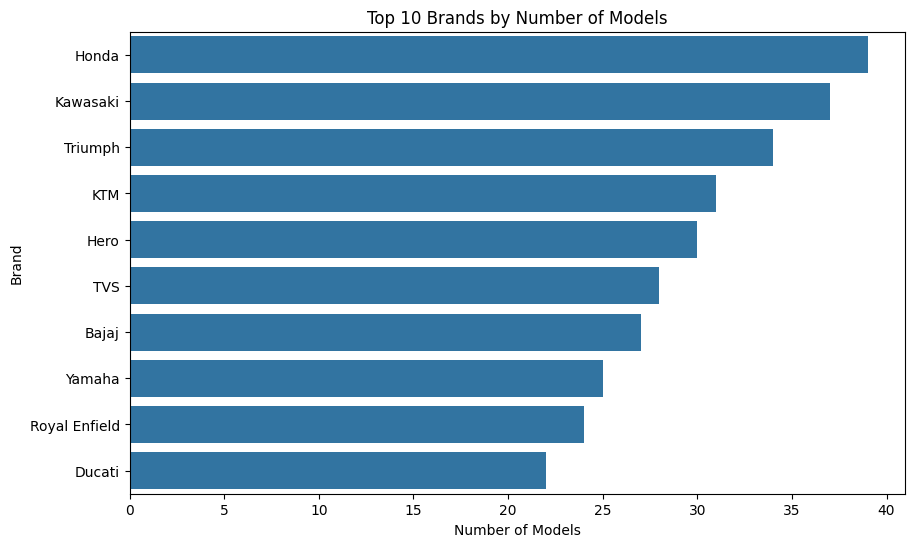

In [230]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=brand_counts.values,
    y=brand_counts.index
)

plt.title("Top 10 Brands by Number of Models")
plt.xlabel("Number of Models")
plt.ylabel("Brand")

plt.show()

The chart shows the brands with the highest number of models in the dataset. This helps identify which manufacturers have the widest representation in the BikeWale dataset.

Number of models by brand

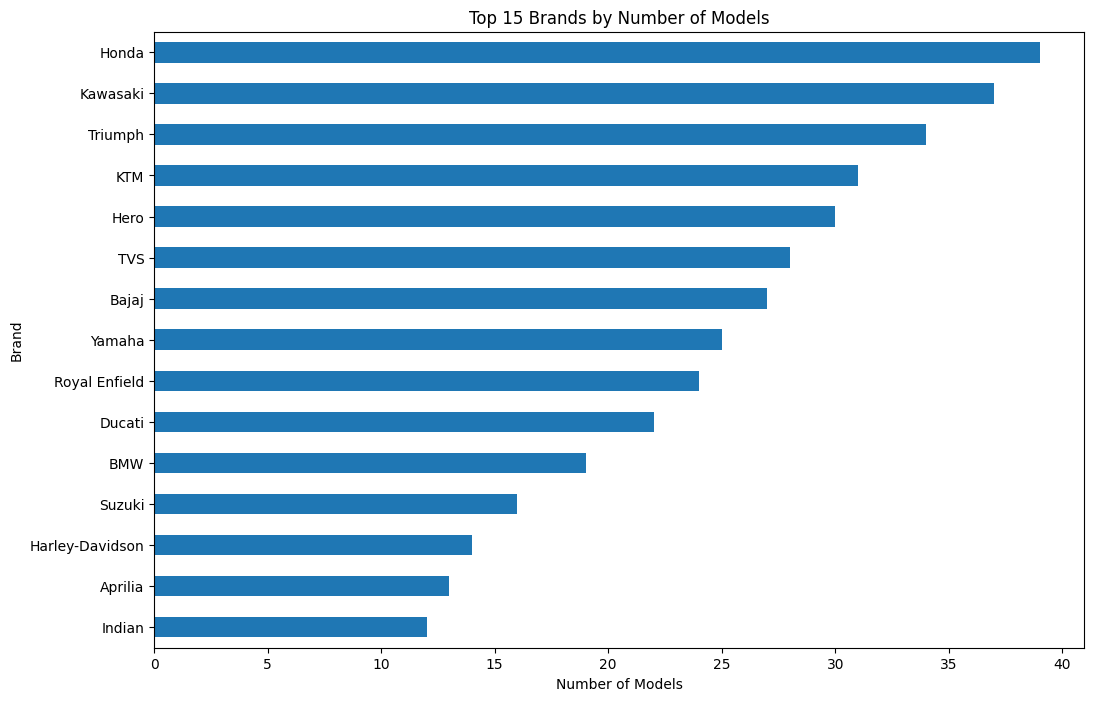

In [231]:
brand_counts = df['brand'].value_counts()

plt.figure(figsize=(12, 8))

brand_counts.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Brands by Number of Models")
plt.xlabel("Number of Models")
plt.ylabel("Brand")

plt.show()

Petrol vs Electric bikes

In [232]:
fuel_counts = df['fuel_type'].value_counts()

fuel_counts

,count
fuel_type,
Petrol,414
Electric,108


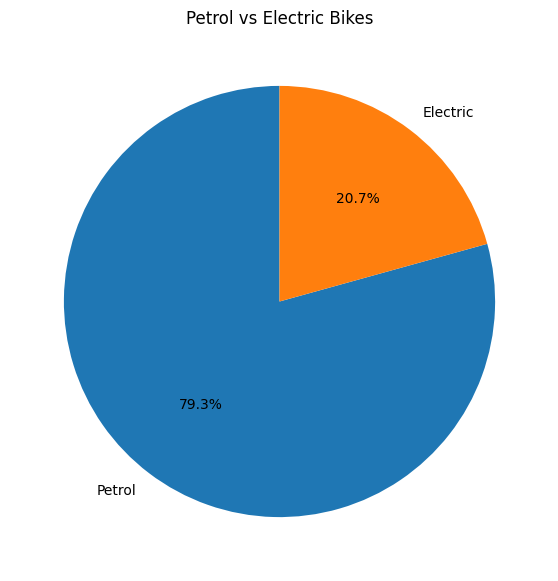

In [233]:
plt.figure(figsize=(7, 7))

plt.pie(
    fuel_counts.values,
    labels=fuel_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Petrol vs Electric Bikes")

plt.show()

Average price by brand

In [234]:
avg_price_brand = (
    df_price
    .groupby('brand')['price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

avg_price_brand

,price
brand,
Ducati,2.893034e+06
Harley-Davidson,2.306806e+06
BMW,1.907317e+06
Indian,1.732763e+06
Moto Guzzi,1.645802e+06
Triumph,1.176077e+06
Aprilia,8.895050e+05
Kawasaki,8.018535e+05
KTM,6.916542e+05


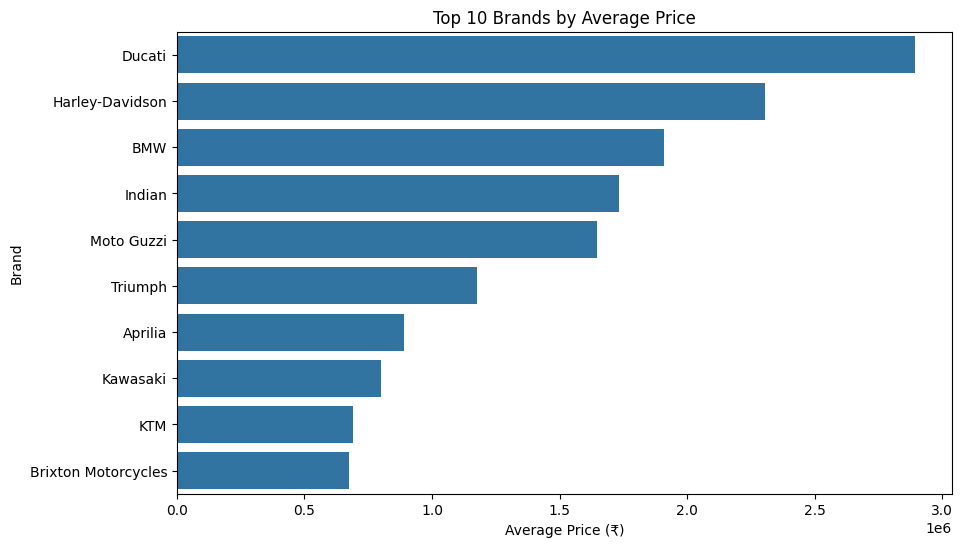

In [235]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=avg_price_brand.values,
    y=avg_price_brand.index
)

plt.title("Top 10 Brands by Average Price")
plt.xlabel("Average Price (₹)")
plt.ylabel("Brand")

plt.show()

Most expensive bikes

In [236]:
expensive_bikes = (
    df_price[
        ['brand', 'model', 'price']
    ]
    .sort_values('price', ascending=False)
    .head(10)
)

expensive_bikes

,brand,model,price
356,Ducati,Panigale V4 Lamborghini,10000000
358,Ducati,Panigale V4 R,8499000
391,Harley-Davidson,Road Glide,4575000
26,Honda,Goldwing,4430000
371,Ducati,Multistrada V4 RS,4346700
396,Harley-Davidson,Street Glide,4250000
338,BMW,K 1600,3800000
263,Kawasaki,Ninja H2 SX SE,3627783
392,Harley-Davidson,Breakout,3436000
25,Honda,CBR1000RR-R Fireblade,3350000


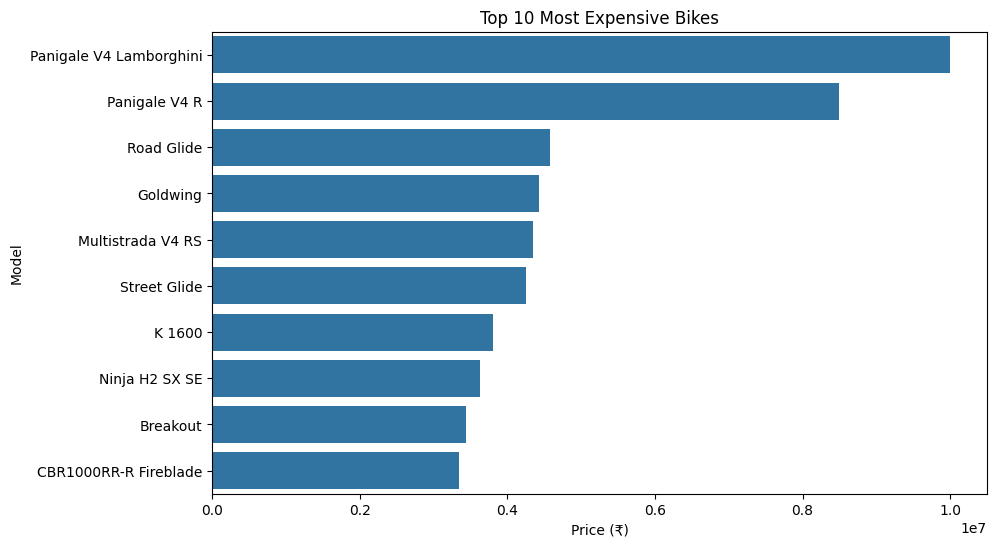

In [237]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=expensive_bikes,
    x='price',
    y='model'
)

plt.title("Top 10 Most Expensive Bikes")
plt.xlabel("Price (₹)")
plt.ylabel("Model")

plt.show()

Cheapest bikes

In [238]:
cheapest_bikes = (
    df_price[
        ['brand', 'model', 'price']
    ]
    .sort_values('price')
    .head(10)
)

cheapest_bikes

,brand,model,price
75,TVS,XL 100 Heavy Duty,47922
435,Lectrix,SX25,54999
379,Evolet,Pony,55799
122,Hero,HF Deluxe,58721
82,TVS,XL 100 Comfort,60380
423,Joy e-bike,Gen Nxt,60827
424,Joy e-bike,Wolf,61877
457,Okinawa,R30,61998
78,TVS,Sport,65729
13,Honda,Shine 100,66002


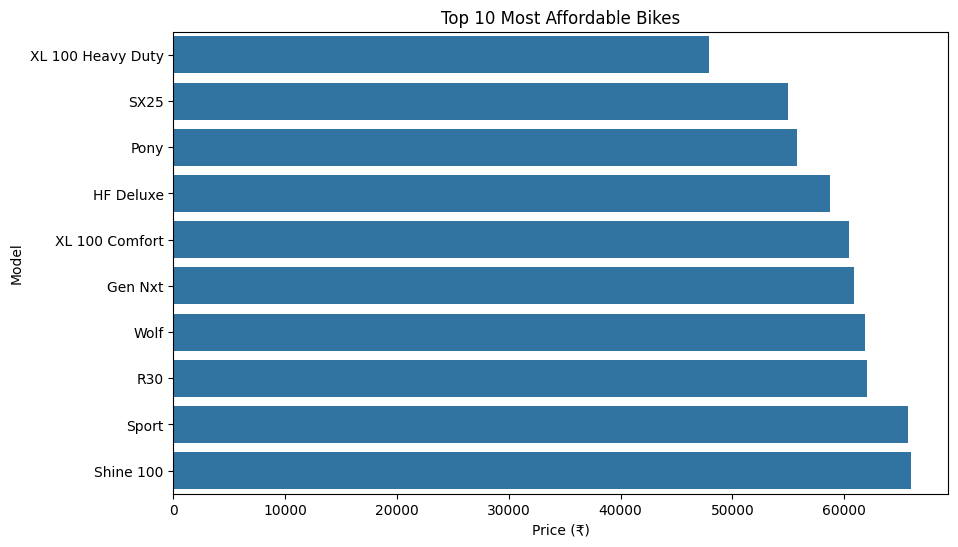

In [239]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cheapest_bikes,
    x='price',
    y='model'
)

plt.title("Top 10 Most Affordable Bikes")
plt.xlabel("Price (₹)")
plt.ylabel("Model")

plt.show()

Price distribution

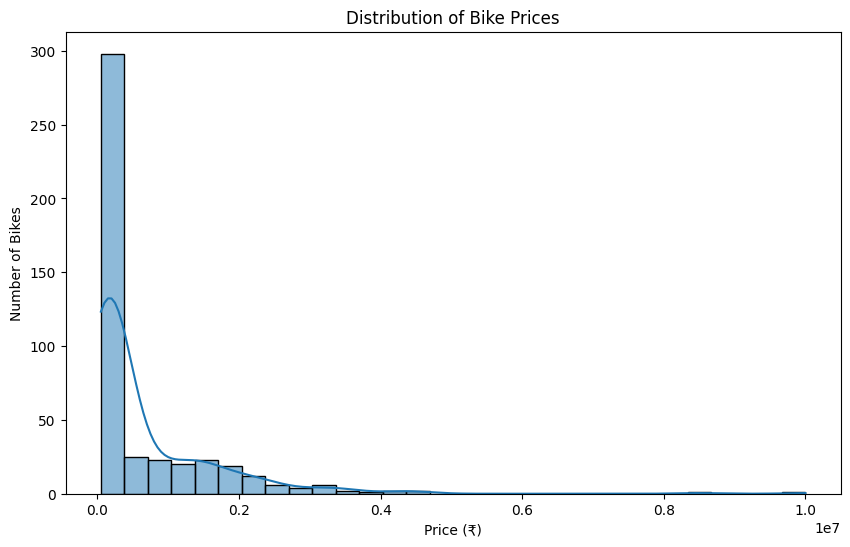

In [240]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_price,
    x='price',
    bins=30,
    kde=True
)

plt.title("Distribution of Bike Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Bikes")

plt.show()

You can identify whether bikes are concentrated in lower, middle, or premium price ranges.

Price distribution using lakhs

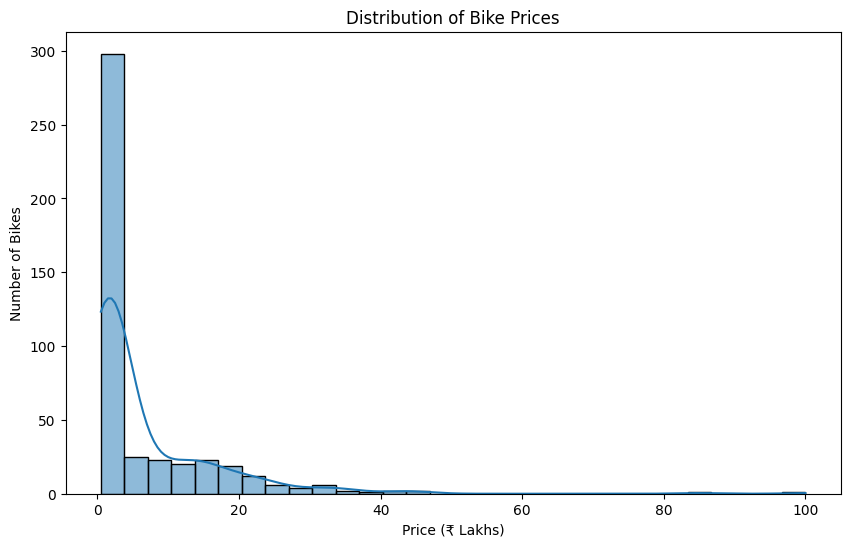

In [241]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_price,
    x='price_lakh',
    bins=30,
    kde=True
)

plt.title("Distribution of Bike Prices")
plt.xlabel("Price (₹ Lakhs)")
plt.ylabel("Number of Bikes")

plt.show()

Rating distribution

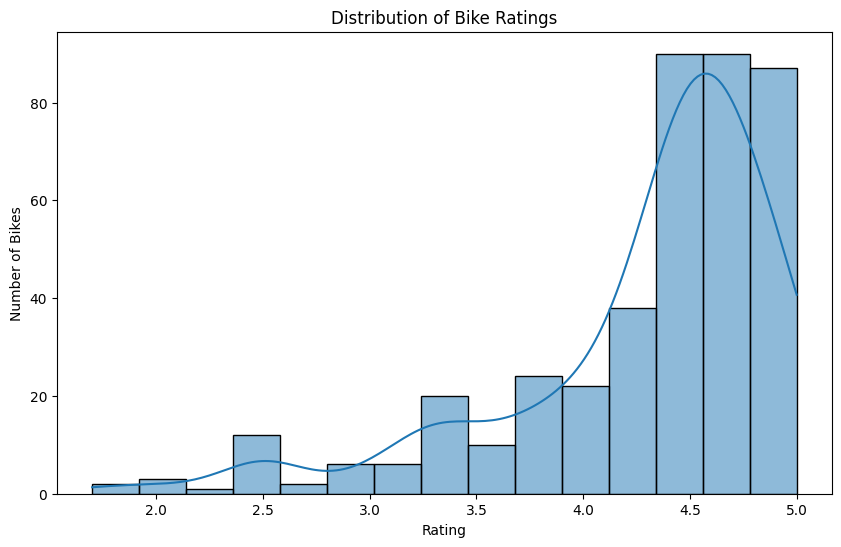

In [242]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='rating',
    bins=15,
    kde=True
)

plt.title("Distribution of Bike Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Bikes")

plt.show()

Average rating by brand

In [243]:
brand_rating = (
    df.groupby('brand')
      .agg(
          model_count=('model', 'count'),
          average_rating=('rating', 'mean')
      )
)

brand_rating = brand_rating[
    brand_rating['model_count'] >= 3
]

brand_rating = (
    brand_rating
    .sort_values('average_rating', ascending=False)
    .head(10)
)

brand_rating

,model_count,average_rating
brand,,
Indian,12,4.937500
Husqvarna,3,4.800000
Benelli,7,4.775000
Zontes,4,4.625000
Suzuki,16,4.584615
Royal Enfield,24,4.570588
BMW,19,4.553333
KTM,31,4.542857
Lectrix,4,4.500000


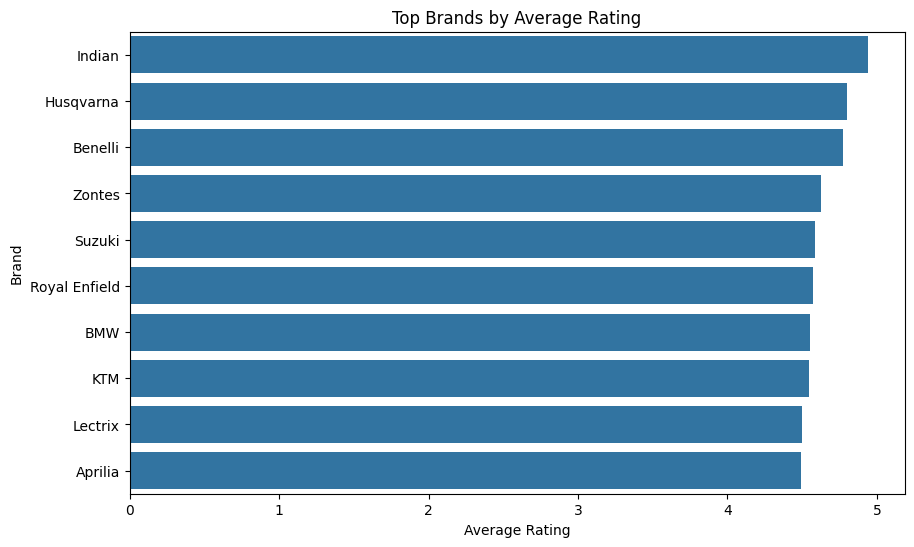

In [244]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=brand_rating,
    x='average_rating',
    y=brand_rating.index
)

plt.title("Top Brands by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Brand")

plt.show()

Top bikes by mileage

In [247]:
top_mileage = (
    df[
        ['brand', 'model', 'mileage_kmpl']
    ]
    .dropna(subset=['mileage_kmpl'])
    .sort_values('mileage_kmpl', ascending=False)
    .head(10)
)

top_mileage

,brand,model,mileage_kmpl
105,Bajaj,Freedom,91.0
111,Bajaj,Platina 100,75.0
78,TVS,Sport,70.0
83,TVS,Star City Plus,70.0
113,Bajaj,Platina 110,70.0
112,Bajaj,CT 110,70.0
13,Honda,Shine 100,65.0
122,Hero,HF Deluxe,65.0
131,Hero,Super Splendor Xtec 2.0,65.0
127,Hero,Splendor Plus Xtec,65.0


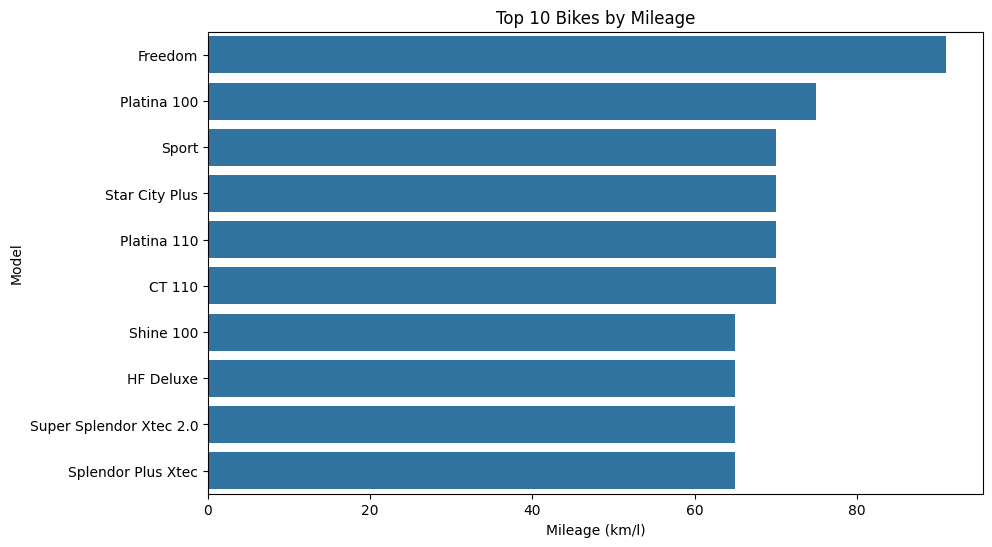

In [248]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_mileage,
    x='mileage_kmpl',
    y='model'
)

plt.title("Top 10 Bikes by Mileage")
plt.xlabel("Mileage (km/l)")
plt.ylabel("Model")

plt.show()

Electric bikes by brand

In [249]:
electric_brand = (
    df[df['fuel_type'] == 'Electric']
    ['brand']
    .value_counts()
    .head(10)
)

electric_brand

,count
brand,
Okinawa,8
OLA,7
Odysse,6
Ather,5
BGauss,4
Ampere,4
Joy e-bike,4
OPG Mobility,4
Revolt,4


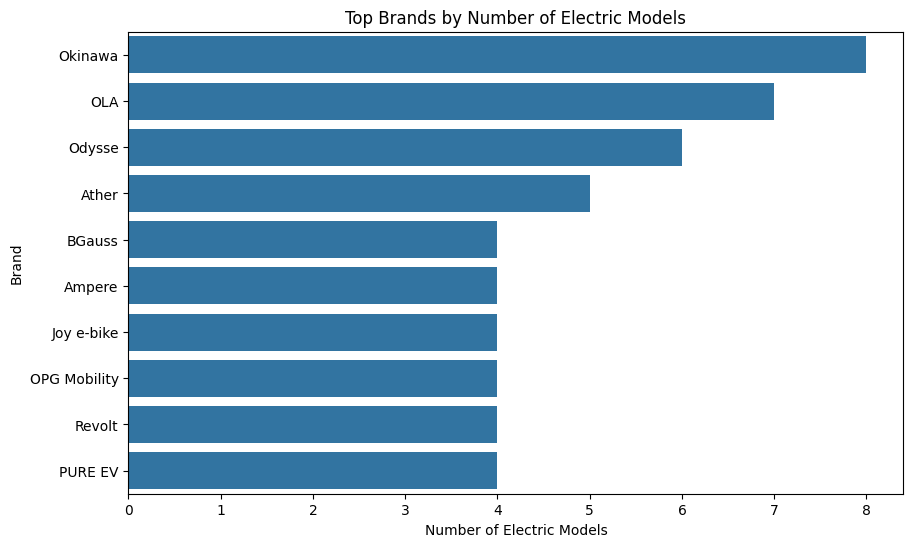

In [250]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=electric_brand.values,
    y=electric_brand.index
)

plt.title("Top Brands by Number of Electric Models")
plt.xlabel("Number of Electric Models")
plt.ylabel("Brand")

plt.show()

Correlation heatmap

In [251]:
correlation_columns = [
    'price',
    'rating',
    'review_count',
    'mileage_kmpl',
    'displacement_cc',
    'max_power_bhp',
    'kerb_weight_kg',
    'charging_time_hours',
    'max_power_kw'
]

corr = df[correlation_columns].corr()

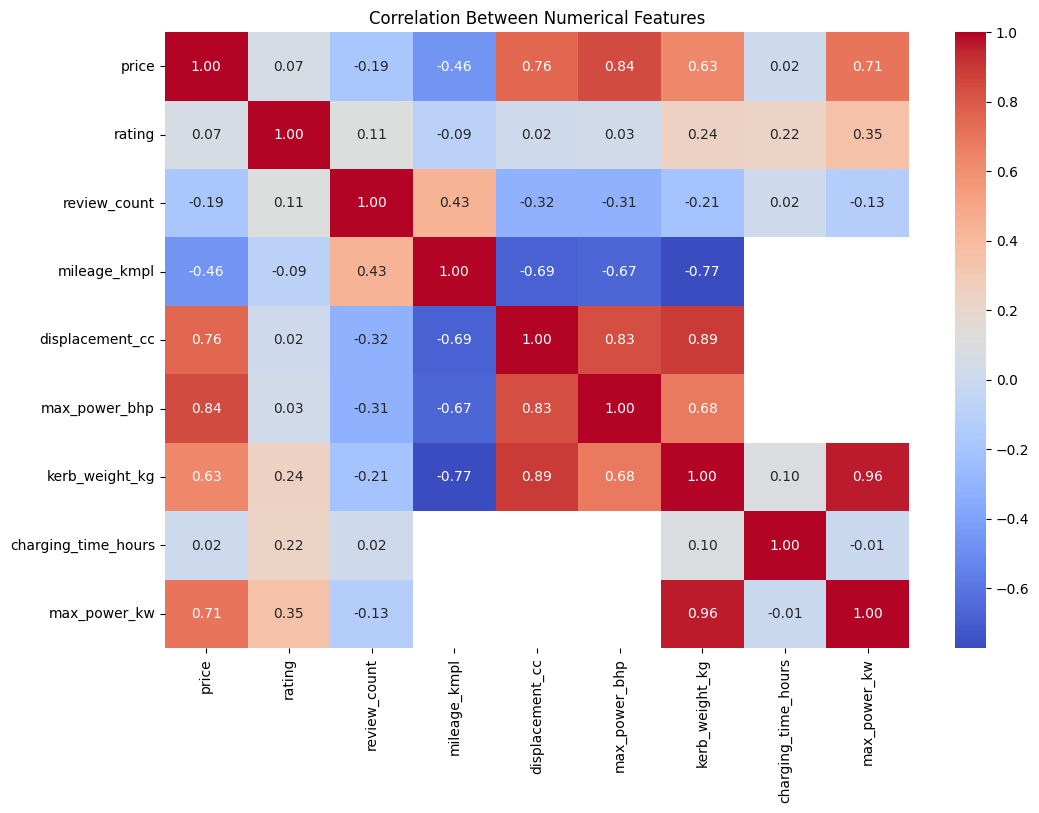

In [252]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Numerical Features")

plt.show()

A very useful summary table

In [253]:
summary = {
    'Total Bikes': len(df),
    'Total Brands': df['brand'].nunique(),
    'Electric Bikes': (df['fuel_type'] == 'Electric').sum(),
    'Petrol Bikes': (df['fuel_type'] == 'Petrol').sum(),
    'Average Rating': df['rating'].mean(),
    'Average Price': df_price['price'].mean(),
    'Minimum Price': df_price['price'].min(),
    'Maximum Price': df_price['price'].max(),
    'Average Mileage': df['mileage_kmpl'].mean(),
    'Average Power': df['max_power_bhp'].mean()
}

summary

{'Total Bikes': 522,
 'Total Brands': 61,
 'Electric Bikes': np.int64(108),
 'Petrol Bikes': np.int64(414),
 'Average Rating': np.float64(4.290556900726393),
 'Average Price': np.float64(655776.0269662922),
 'Minimum Price': 47922,
 'Maximum Price': 10000000,
 'Average Mileage': np.float64(38.58009708737864),
 'Average Power': np.float64(54.481651376146786)}

In [254]:
summary_df = pd.DataFrame(
    summary.items(),
    columns=['Metric', 'Value']
)

summary_df

,Metric,Value
0,Total Bikes,5.220000e+02
1,Total Brands,6.100000e+01
2,Electric Bikes,1.080000e+02
3,Petrol Bikes,4.140000e+02
4,Average Rating,4.290557e+00
5,Average Price,6.557760e+05
6,Minimum Price,4.792200e+04
7,Maximum Price,1.000000e+07
8,Average Mileage,3.858010e+01
9,Average Power,5.448165e+01
